# Notebook 12: Intelligent Prescription Feature Engineering

## Scientific Objective
Design, construct, and validate strictly pre-decision feature representations for intelligent prescription, satisfying **Workstream 3**.

We implement:
1. Dataset profile features (size, feature counts, class imbalance).
2. Drift severity and topology diagnostics (severity score, affected feature ratio, localized slice presence).
3. Adaptation budget and resource constraints ($B$, $B/P$, memory/time limits).
4. Candidate repair configuration and interaction terms ($K$, $K/(B+1)$).
5. Feature scaling, categorical encoding, and zero-leakage correlation analysis.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from component3.src.prescription.candidate_ranker import (
    PRE_DECISION_CAT_COLS,
    PRE_DECISION_NUM_COLS,
    CandidateFeatureEncoder,
)

REPO_ROOT = Path.cwd()
df = pd.read_csv(REPO_ROOT / "component3" / "results" / "expanded_prescription_training_dataset.csv")

print(f"Loaded dataset: {df.shape}")
print(f"Numerical pre-decision features ({len(PRE_DECISION_NUM_COLS)}):", PRE_DECISION_NUM_COLS)
print(f"Categorical pre-decision features ({len(PRE_DECISION_CAT_COLS)}):", PRE_DECISION_CAT_COLS)


Loaded dataset: (337, 34)
Numerical pre-decision features (12): ['in_dataset_num_features', 'in_dataset_num_numerical', 'in_dataset_num_categorical', 'in_dataset_imbalance_ratio', 'in_drift_severity_score', 'in_affected_feature_proportion', 'in_available_adaptation_budget', 'in_budget_to_feature_ratio', 'in_has_valid_diagnostic_slice', 'in_diagnostic_slice_size', 'arm_candidate_quantity', 'arm_synth_to_auth_ratio']
Categorical pre-decision features (4): ['in_drift_category', 'in_source_model_family', 'arm_candidate_strategy', 'arm_candidate_generator']


## 1. Feature Descriptions and Distributions
Let us inspect the distribution of numerical pre-decision features:


In [2]:
df[PRE_DECISION_NUM_COLS].describe().T[["mean", "std", "min", "50%", "max"]]


,mean,std,min,50%,max
in_dataset_num_features,16.777448,3.263392,12.000,19.000,19.000
in_dataset_num_numerical,5.540059,2.503396,3.000,5.000,9.000
in_dataset_num_categorical,11.237389,3.809062,7.000,10.000,16.000
in_dataset_imbalance_ratio,0.208484,0.066100,0.113,0.239,0.265
in_drift_severity_score,0.528932,0.048960,0.500,0.500,0.650
in_affected_feature_proportion,0.560237,0.323702,0.200,0.500,1.000
in_available_adaptation_budget,152.670623,72.222301,0.000,200.000,200.000
in_budget_to_feature_ratio,9.506593,5.085707,0.000,10.526,16.667
in_has_valid_diagnostic_slice,0.323442,0.468485,0.000,0.000,1.000
in_diagnostic_slice_size,15.281899,23.068107,0.000,0.000,50.000


## 2. Correlation Analysis with Utility and Acceptance
We examine the linear and rank correlation between pre-decision features and target outcomes (`out_delta_f1_vs_baseline` and `out_is_accepted`).


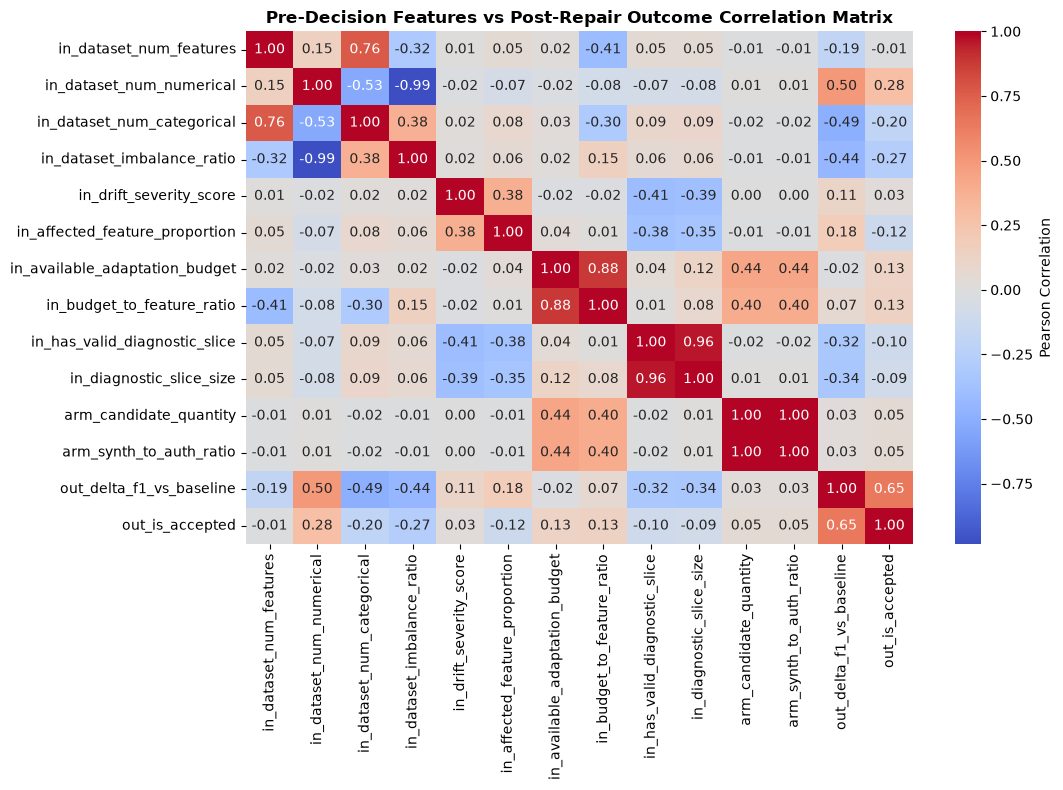

In [3]:
corr_cols = PRE_DECISION_NUM_COLS + ["out_delta_f1_vs_baseline", "out_is_accepted"]
corr_mat = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar_kws={"label": "Pearson Correlation"}, ax=ax)
plt.title("Pre-Decision Features vs Post-Repair Outcome Correlation Matrix", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


## 3. Analysis of Interaction Terms
Key engineered interaction terms:
1. `in_budget_to_feature_ratio` ($B / P$): Measures sample density per feature. When $B / P < 2$, deep generative modeling faces severe data scarcity.
2. `arm_synth_to_auth_ratio` ($K / (B + 1)$): Measures synthetic augmentation ratio relative to authentic data.


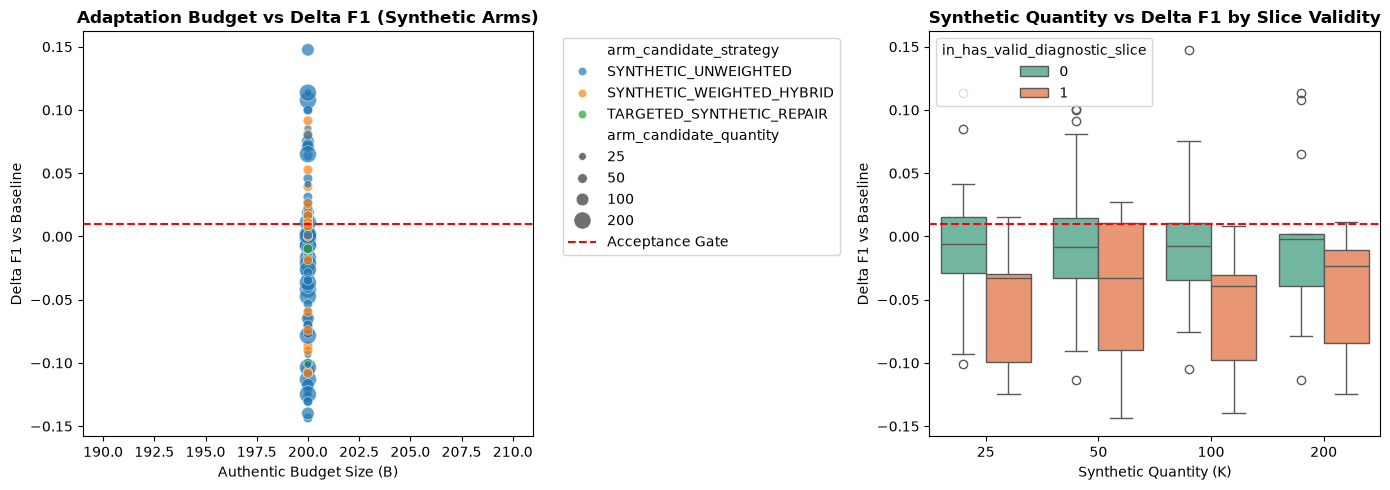

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=df[df["arm_candidate_quantity"] > 0],
    x="in_available_adaptation_budget",
    y="out_delta_f1_vs_baseline",
    hue="arm_candidate_strategy",
    size="arm_candidate_quantity",
    sizes=(30, 150),
    alpha=0.7,
    ax=ax1
)
ax1.axhline(0.01, color="red", linestyle="--", label="Acceptance Gate")
ax1.set_title("Adaptation Budget vs Delta F1 (Synthetic Arms)", fontweight="bold")
ax1.set_xlabel("Authentic Budget Size (B)")
ax1.set_ylabel("Delta F1 vs Baseline")
ax1.legend(bbox_to_anchor=(1.05, 1), loc="upper left")

sns.boxplot(
    data=df[df["arm_candidate_quantity"] > 0],
    x="arm_candidate_quantity",
    y="out_delta_f1_vs_baseline",
    hue="in_has_valid_diagnostic_slice",
    ax=ax2,
    palette="Set2"
)
ax2.axhline(0.01, color="red", linestyle="--")
ax2.set_title("Synthetic Quantity vs Delta F1 by Slice Validity", fontweight="bold")
ax2.set_xlabel("Synthetic Quantity (K)")
ax2.set_ylabel("Delta F1 vs Baseline")

plt.tight_layout()
plt.show()


## 4. Feature Pipeline Transformation Test
We verify that `CandidateFeatureEncoder` cleanly transforms the dataset into a dense matrix suitable for regularized regression and ensemble trees without missing values or data snooping.


In [5]:
encoder = CandidateFeatureEncoder()
encoder.fit(df)
X = encoder.transform(df)

print(f"Input DataFrame shape: {df.shape}")
print(f"Encoded feature matrix X shape: {X.shape}")
print(f"Total encoded features: {len(encoder.feature_names_)}")
print("First 15 encoded feature names:")
for name in encoder.feature_names_[:15]:
    print(f"  - {name}")


Input DataFrame shape: (337, 34)
Encoded feature matrix X shape: (337, 32)
Total encoded features: 32
First 15 encoded feature names:
  - in_dataset_num_features
  - in_dataset_num_numerical
  - in_dataset_num_categorical
  - in_dataset_imbalance_ratio
  - in_drift_severity_score
  - in_affected_feature_proportion
  - in_available_adaptation_budget
  - in_budget_to_feature_ratio
  - in_has_valid_diagnostic_slice
  - in_diagnostic_slice_size
  - arm_candidate_quantity
  - arm_synth_to_auth_ratio
  - in_drift_category_categorical_distribution_shift
  - in_drift_category_class_prior_shift
  - in_drift_category_concept_drift


## Summary & Readiness
- The 12 numerical and 4 categorical features encompass all information available prior to model adaptation.
- Engineered interaction features ($B/P$ and $K/(B+1)$) capture capacity and augmentation scale.
- Feature pipeline is fully encapsulated in `CandidateFeatureEncoder`.
